# 05 — Image model for d1: reproducible B0 pilot

This notebook establishes a reliable image-training pipeline and compares four
EfficientNet-B0 settings on patients kept out of fitting. Its immediate question
is: **does the pipeline work, how fast is training, and which settings deserve a
longer inner-validation experiment?**

It reuses the patient folds from stage 02 and shared Python utilities. The WIP
notebook and its checkpoints preserve the historical experiment. Later stages
compare augmentation, preprocessing and architecture families before final
five-outer/three-inner evaluation. See `docs/image_methodology.md` for the rules.

The pilot excludes outer fold 0. Its inner validation labels choose epochs and
settings, so these scores are exploratory and must not be presented as final OOF
performance. The reserved test is outside this workflow.


## Setup

Use the project's CUDA-enabled `.venv`. The default reads saved pilot results;
set `TRAIN_PILOT=True` only to start or resume the bounded six-epoch comparison.
The shared CLI can also run training independently of the notebook:

```powershell
.venv/Scripts/python.exe scripts/run_image_pilot.py --config configs/image_model.yaml --resume
```

The implementation registers B0, weak augmentation and unchanged preprocessing.
The later adapters are declared in configuration and documentation, but cannot
silently execute as part of this pilot.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown

PROJECT_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                     if (path / "configs/image_model.yaml").is_file()
                     and (path / "src/melanoma_detection").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start the notebook inside the ADS2002-Melanoma project.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from melanoma_detection.image_pilot import load_config, prepare_pilot, run_pilot
from melanoma_detection.metadata_evaluation import probability_metrics
from melanoma_detection.image_reporting import (
    load_histories, plot_learning_curves, plot_reliability_checks,
    plot_augmentation_preview,
)

CONFIG_PATH = PROJECT_ROOT / "configs/image_model.yaml"
TRAIN_PILOT = False
config = load_config(CONFIG_PATH)
plt.rcParams.update({"font.size": 10, "figure.facecolor": "white", "axes.facecolor": "white"})
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Run:", config["run"]["run_id"], "| Training enabled:", TRAIN_PILOT)


Python: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\.venv\Scripts\python.exe
PyTorch: 2.14.0+cu130 | CUDA: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Run: b0_pilot_v1 | Training enabled: False


## Data and patient isolation

Audit all required d1 images for missing files, decoding problems and exact
duplicate content. Split only the outer-training patients into three inner
folds. Each patient's images stay together. No age, sex, site, diagnosis or
patient identifier is supplied as a model feature.

`images` counts lesions; `patients` counts people; `malignant_images` counts
labelled melanoma images. The excluded outer patients are never predicted by
this pilot. The saved split membership is part of the checkpoint identity.


In [2]:
prepared = prepare_pilot(PROJECT_ROOT, config, audit_images=True)
run_dir = Path(prepared["run_dir"])
partitions = {
    "fitting": prepared["fitting"],
    "inner_validation": prepared["validation"],
    "outer_excluded": prepared["outer_excluded"],
}
split_counts = pd.DataFrame([
    {"partition": name, "images": len(frame), "patients": frame.patient_id.nunique(),
     "malignant_images": int(frame.target.sum()) if name != "outer_excluded" else np.nan,
     "malignancy_rate": frame.target.mean() if name != "outer_excluded" else np.nan}
    for name, frame in partitions.items()
])
display(split_counts.style.format({"malignancy_rate": "{:.2%}"}, na_rep="Not used"))
fitting_patients = set(partitions["fitting"].patient_id)
validation_patients = set(partitions["inner_validation"].patient_id)
outer_patients = set(partitions["outer_excluded"].patient_id)
assert fitting_patients.isdisjoint(validation_patients)
assert fitting_patients.isdisjoint(outer_patients)
assert validation_patients.isdisjoint(outer_patients)
audit_counts = {key: value for key, value in prepared["image_audit"].items()
                if isinstance(value, (str, int, float, bool)) or value is None}
audit_counts["exact_duplicate_groups_same_patient"] = len(
    prepared["image_audit"]["duplicate_groups_within_patient"])
display(pd.DataFrame([audit_counts]))
print("Patient overlaps: 0. Reserved test loaded: False.")


,partition,images,patients,malignant_images,malignancy_rate
0,fitting,3660,225,70.000000,1.91%
1,inner_validation,1834,113,33.000000,1.80%
2,outer_excluded,1370,84,Not used,Not used


,status,images,patients,crosspatient_duplicate_groups,label_conflicts,duplicate_policy,exact_duplicate_groups_same_patient
0,complete,6864,422,0,0,Retain label-consistent duplicates within the ...,158


Patient overlaps: 0. Reserved test loaded: False.


## Preparation and training recipe

The weak augmentation preserves the existing WIP preparation: whole-image
224-pixel resize, horizontal/vertical flips, rotation by at most 20 degrees and
ImageNet normalisation. It has no colour jitter. Ordinary prediction preparation
uses only deterministic resizing and normalisation.

The preview deliberately includes melanoma and benign images from fitting
patients. Check lesion boundaries, pigmentation and texture; it is a QA sample,
not a representation of class prevalence.

The inspected preview retains the existing rotation's black corners. Rotation
can remove peripheral pixels; the six sampled lesions retain visible central
texture and pigmentation. This limited check does not certify every transformed
image. The later stronger-augmentation comparison must review lesion framing
and reflection padding explicitly.


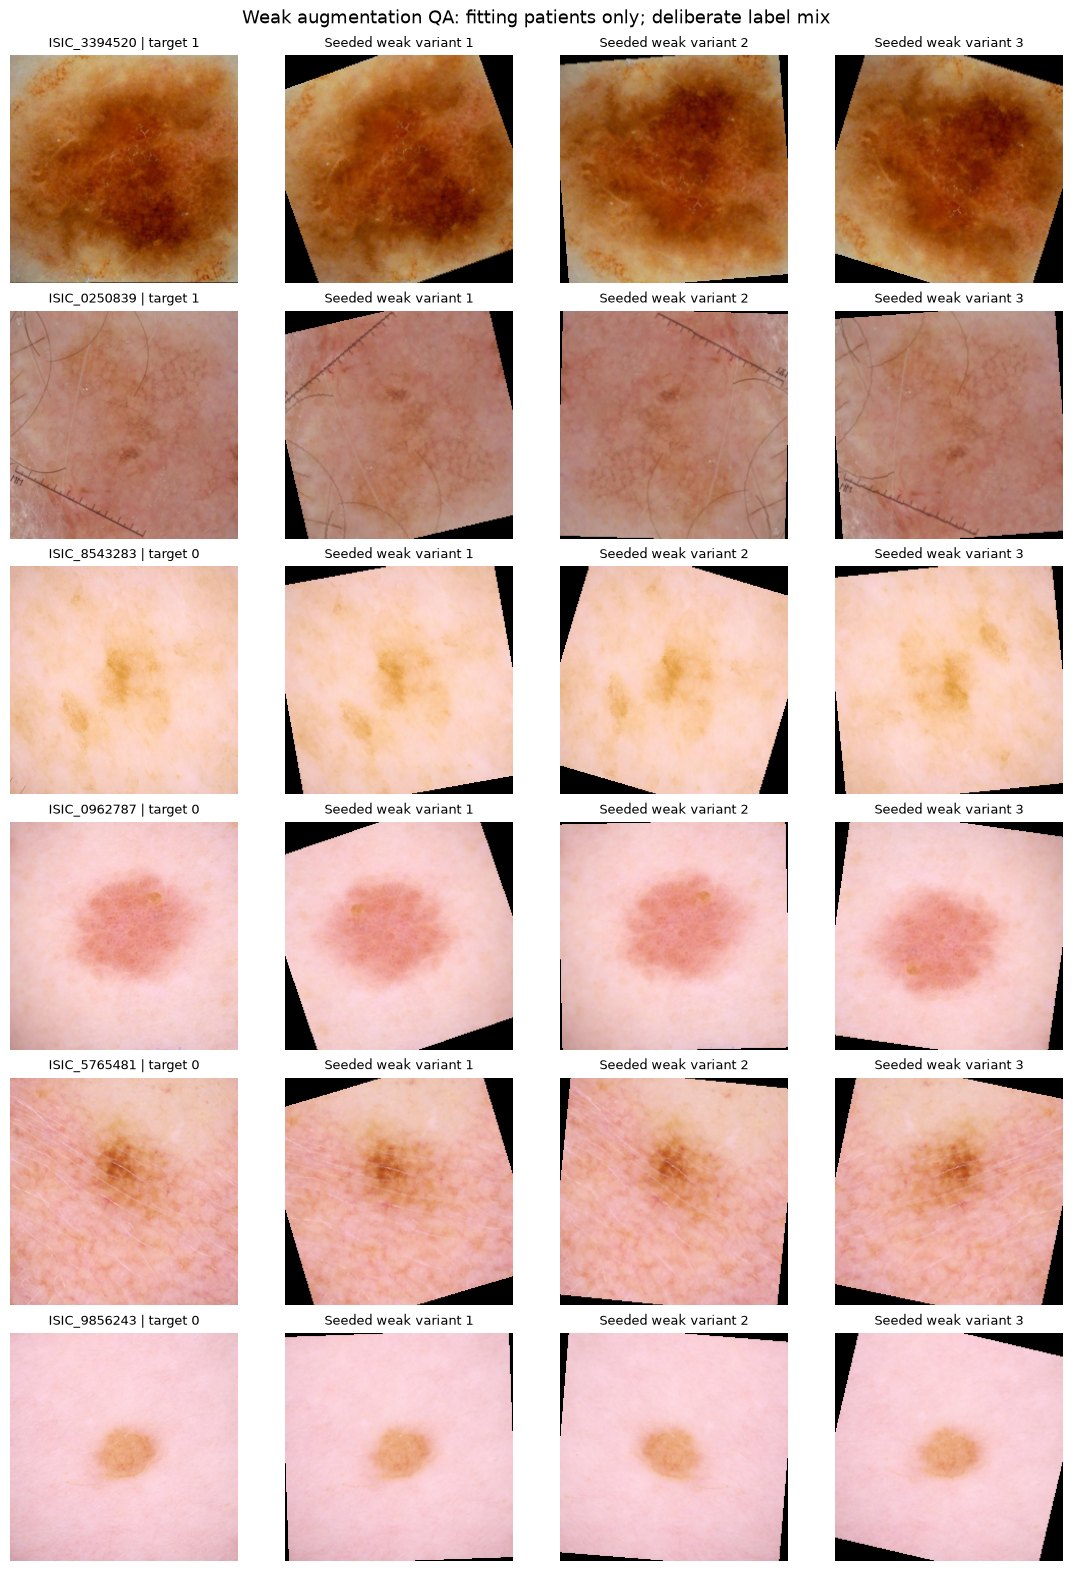

In [3]:
preview = plot_augmentation_preview(prepared["fitting"], config["model"])
plt.show()


One warmup epoch updates only the new classifier. Fine-tuning then updates
features with a smaller backbone learning rate. BatchNorm statistics and affine
parameters stay frozen. AMP reduces GPU memory use; gradient accumulation keeps
the effective batch at 64 if memory requires a smaller microbatch.

The four recipes vary backbone learning rate and loss weighting. Moderate
weighting is the square root of the fitting negative/positive ratio. It can
change score calibration. Do not interpret a raw 0.70 score as verified 70% risk.

The cosine schedule is fixed to the later 30-epoch horizon, so extending a
compatible checkpoint does not retime the pilot's earlier learning rates.


In [4]:
recipes = config["candidates"]["pilot_recipes"]
display(pd.DataFrame(recipes))
positive_count = int(prepared["fitting"].target.sum())
negative_count = len(prepared["fitting"]) - positive_count
print(f"Fitting positives: {positive_count}; negatives: {negative_count}; "
      f"moderate positive weight: {np.sqrt(negative_count / positive_count):.3f}")
display(pd.DataFrame([config["training"]]))


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


Fitting positives: 70; negatives: 3590; moderate positive weight: 7.161


,microbatch,effective_batch,min_microbatch,head_lr,weight_decay,warmup_epochs,schedule_epochs,min_lr_factor,gradient_clip,amp,num_workers,seed
0,64,64,4,0.001,0.0001,1,30,0.1,1.0,True,0,42


## Run or inspect the pilot

All recipes receive six epochs on the same patient split and seed. The budget
stops between epochs and preserves a resumable checkpoint. An unfinished trial
makes the comparison incomplete; no winner is declared from unequal horizons.

The default below loads saved outputs. It does not train, fit calibration or
select a threshold. Prediction-only checks are available through the CLI and
preserve the histories.


In [5]:
if TRAIN_PILOT:
    summary = run_pilot(PROJECT_ROOT, config, resume=True, prepared=prepared, device="cuda")
else:
    summary_path = run_dir / "summary.json"
    if not summary_path.is_file():
        raise FileNotFoundError("No saved pilot yet. Run the CLI above, or enable TRAIN_PILOT.")
    saved_manifest = json.loads((run_dir / "run_manifest.json").read_text(encoding="utf-8"))
    if saved_manifest["compatibility_sha256"] != prepared["manifest"]["compatibility_sha256"]:
        raise ValueError("Saved pilot is incompatible with current data/configuration/code/environment.")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
print("Status:", summary["status"])
print("All four six-epoch trials complete:", summary["comparison_complete"])
print("Provisional selection:", summary.get("selected_recipe"))
display(Markdown(summary["recommendation"]))


Status: complete
All four six-epoch trials complete: True
Provisional selection: lr3e5_sqrt


Best inner AP is near the pilot cap; extend all four candidates on inner patients to a 30-epoch cap before stronger claims.

## Results: inner validation, not final evaluation

The best epoch for each recipe maximises inner validation AP; exact ties keep
the earlier epoch. AP and ROC-AUC assess ranking, while log loss and Brier assess
raw score quality. All values below concern the same inner validation patients.
The saved best scores reuse patients involved in epoch selection and are
preliminary evidence.


In [6]:
history = load_histories(run_dir)
if history.empty:
    raise RuntimeError("The pilot has no completed epochs to inspect.")
best_rows = history.sort_values(["recipe_id", "average_precision", "epoch"],
                                ascending=[True, False, True]).groupby("recipe_id").head(1)
columns = ["recipe_id", "epoch", "average_precision", "roc_auc", "log_loss", "brier"]
display(best_rows[columns].sort_values("recipe_id").style.format(
    {key: "{:.4f}" for key in columns[2:]}))
constant_score = np.full(len(prepared["validation"]), prepared["fitting"].target.mean())
baseline = probability_metrics(prepared["validation"].target, constant_score)
display(pd.DataFrame([{"reference": "Constant fitting-prevalence score", **baseline}]).style.format(
    {key: "{:.4f}" for key in baseline}))
display(history.groupby("recipe_id").agg(
    completed_epochs=("epoch", "max"), mean_epoch_seconds=("epoch_seconds", "mean"),
    peak_memory_GB=("peak_memory_bytes", lambda values: values.max() / 2**30),
    microbatch=("microbatch", "min"),
    skipped_AMP_updates=("skipped_optimizer_updates", "sum"),
).style.format({"mean_epoch_seconds": "{:.1f}", "peak_memory_GB": "{:.2f}"}))


,recipe_id,epoch,average_precision,roc_auc,log_loss,brier
3,lr1e4_none,4,0.1119,0.8602,0.0763,0.0169
11,lr1e4_sqrt,6,0.1097,0.8734,0.0793,0.0199
16,lr3e5_none,5,0.1155,0.8426,0.0774,0.0170
23,lr3e5_sqrt,6,0.1383,0.8663,0.0876,0.0210


,reference,average_precision,roc_auc,log_loss,brier
0,Constant fitting-prevalence score,0.0180,0.5000,0.0902,0.0177


,completed_epochs,mean_epoch_seconds,peak_memory_GB,microbatch,skipped_AMP_updates
recipe_id,,,,,
lr1e4_none,6,32.9,2.81,64,7
lr1e4_sqrt,6,34.7,2.81,64,8
lr3e5_none,6,34.3,2.81,64,7
lr3e5_sqrt,6,33.1,2.81,64,8


The dotted vertical line separates classifier warmup from fine-tuning. The AP
reference is validation prevalence: a constant score has AP equal to prevalence.
The other panels show ROC-AUC and unweighted probability losses on validation
images. Epoch curves can indicate a plateau, but one split does not establish
generalisation or an optimal duration.


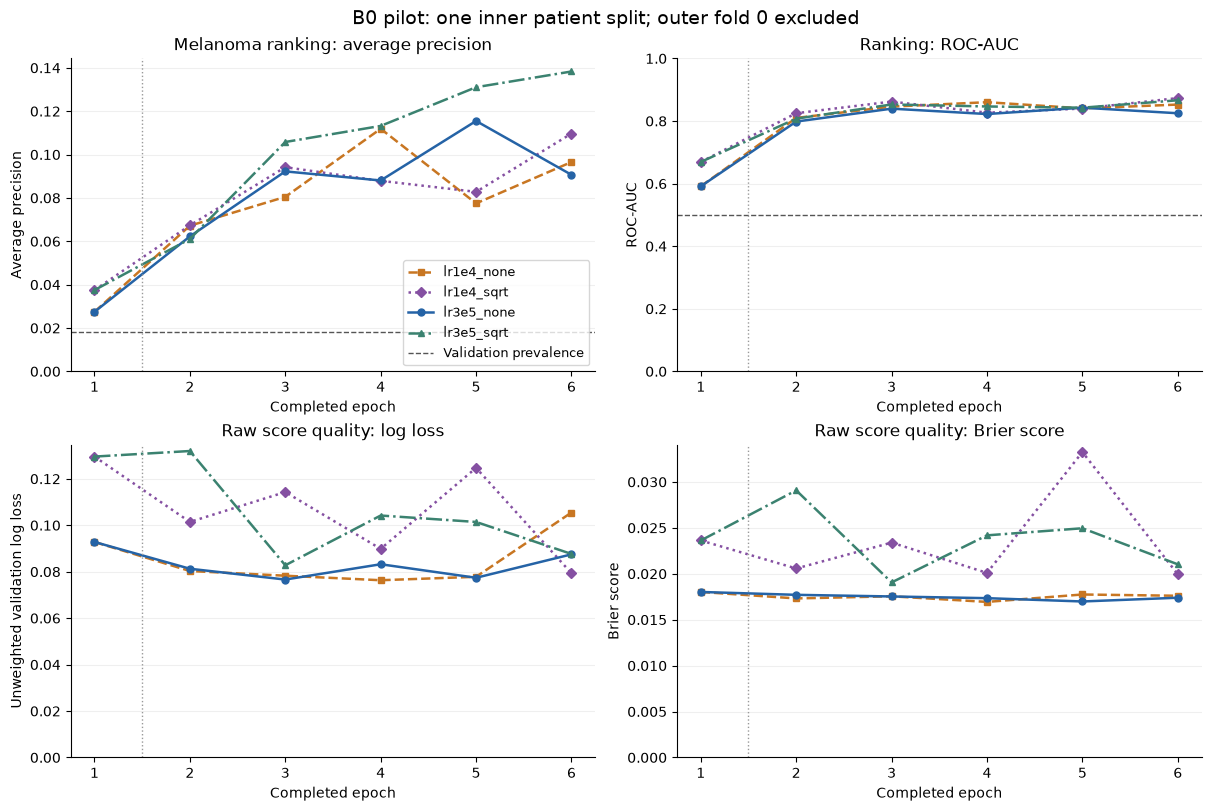

In [7]:
figures_dir = run_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
preparation_receipt = {
    "run_id": config["run"]["run_id"],
    "compatibility_sha256": prepared["manifest"]["compatibility_sha256"],
    "source_sha256": prepared["manifest"]["compatibility"]["source_sha256"],
    "decode": "RGB", "resize": {"size": [224, 224], "interpolation": "bilinear", "antialias": True},
    "preprocessing": "none", "learned_preprocessing_state": None,
    "training_only": {"horizontal_flip_p": .5, "vertical_flip_p": .5,
                      "rotation_degrees": [-20, 20], "rotation_interpolation": "nearest",
                      "rotation_fill": 0, "rotation_expand": False, "colour_jitter": False},
    "normalisation": {"mean": [.485, .456, .406], "std": [.229, .224, .225]},
    "order": ["RGB", "whole_image_resize", "unchanged_preprocessing",
              "training_augmentation_if_fitting", "tensor", "normalisation"],
    "native_pretrained_crop": "256 bicubic resize then 224 centre crop; deliberately overridden",
}
(run_dir / "preparation_specification.json").write_text(
    json.dumps(preparation_receipt, indent=2), encoding="utf-8")
learning = plot_learning_curves(history, prepared["validation"].target.mean())
learning.savefig(figures_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()
preview.savefig(figures_dir / "weak_augmentation_preview.png", dpi=130, bbox_inches="tight")


## Raw-score calibration checks

Each point represents an approximate equal-count score bin. The table below
gives image, melanoma and patient support per bin. The diagonal shows agreement between the mean raw score and observed
melanoma fraction. Bins share patients and may contain very few melanoma images.

These checks describe raw-score quality on epoch-selection patients. They do
not fit a calibrator. The later nested workflow needs training-only OOF scores
for sigmoid calibration and the academic recall-threshold scenario.


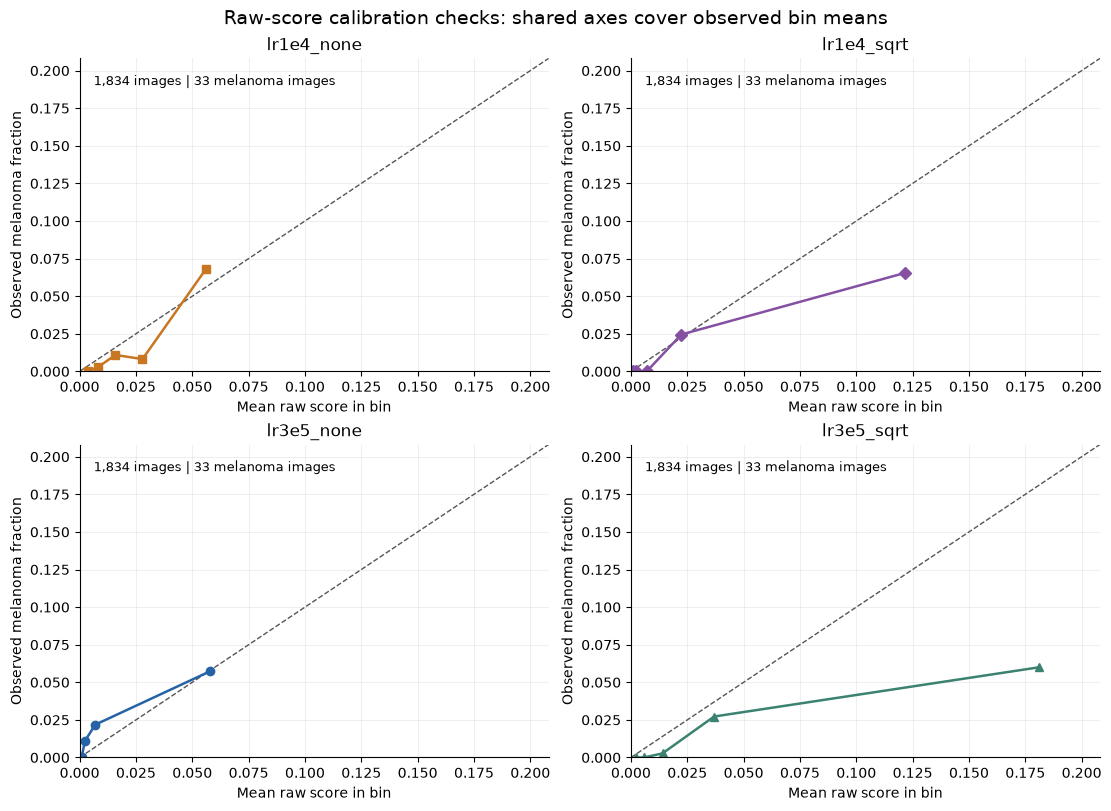

,recipe_id,bin,n_images,n_malignant_images,n_patients,mean_probability,observed_rate
0,lr1e4_none,1,367,0,37,0.0039,0.0000
1,lr1e4_none,2,367,1,68,0.0080,0.0027
2,lr1e4_none,3,366,4,78,0.0159,0.0109
3,lr1e4_none,4,367,3,87,0.0279,0.0082
4,lr1e4_none,5,367,25,77,0.0561,0.0681
5,lr1e4_sqrt,1,367,0,36,0.0009,0.0000
6,lr1e4_sqrt,2,367,0,53,0.0021,0.0000
7,lr1e4_sqrt,3,366,0,82,0.0070,0.0000
8,lr1e4_sqrt,4,367,9,86,0.0224,0.0245
9,lr1e4_sqrt,5,367,24,81,0.1214,0.0654


Saved probabilities belong only to inner validation patients.


In [8]:
reliability = plot_reliability_checks(run_dir)
reliability.savefig(figures_dir / "raw_reliability.png", dpi=150, bbox_inches="tight")
plt.show()
bin_tables = pd.concat([
    pd.read_csv(path).assign(recipe_id=path.parent.name)
    for path in sorted((run_dir / "recipes").glob("*/reliability.csv"))
], ignore_index=True)
display(bin_tables[["recipe_id", "bin", "n_images", "n_malignant_images", "n_patients",
                   "mean_probability", "observed_rate"]].style.format(
    {"mean_probability": "{:.4f}", "observed_rate": "{:.4f}"}))
predictions = pd.concat([
    pd.read_csv(path) for path in sorted((run_dir / "recipes").glob("*/inner_validation_predictions.csv"))
], ignore_index=True)
assert set(predictions.patient_id).isdisjoint(outer_patients)
assert predictions.base_probability.between(0, 1).all()
assert not predictions.duplicated(["recipe_id", "image_id"]).any()
print("Saved probabilities belong only to inner validation patients.")


## Runtime and staged roadmap

The B0 epoch timings include image loading, fitting and validation. Other
architectures have not been timed, so their runtime remains unmeasured. The
expanded final procedure may require 180 logical fits across different models;
do not multiply a B0 speed benchmark into a claimed full completion time.

Later stages are: stronger augmentation; separate hair/lighting experiments;
B0/DenseNet/ConvNeXt comparison; optional Swin if resources permit; final
five-outer/three-inner evaluation. All screening and selection must repeat
inside each outer-training partition. Exploratory winners cannot globally prune
the final candidate library. Budget exhaustion pauses a stage.


In [9]:
display(pd.DataFrame([summary.get("runtime_estimates", {})]))
display(pd.DataFrame(config["roadmap"]["stages"]).T)
print("Later adapters and final evaluation:", config["roadmap"]["status"])
print("Run outputs:", run_dir)


,measured_b0_mean_epoch_seconds,four_30_epoch_b0_fit_hours_same_split,future_nested_maximum_logical_fits,future_nested_maximum_unequal_training_epochs,optional_swin_added_fits,optional_stability_added_fits,future_hours,qualification
0,33.726012,1.1242,180,4380,35,10,None,B0 pilot timing cannot estimate unequal unmeas...


,gpu_hours,max_fits,epochs,minimum_ap_gain,minimum_epochs,patience,patience_ap_delta,maximum_added_nested_gpu_hours,outer_folds,inner_folds,maximum_logical_fits,maximum_training_epochs
augmentation,2.0,2.0,12.0,0.005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preprocessing,4.0,4.0,12.0,0.005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
architecture,12.0,NaN,30.0,NaN,12.0,7.0,0.001,NaN,NaN,NaN,NaN,NaN
optional_swin,6.0,NaN,NaN,NaN,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN
nested,48.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,3.0,180.0,4380.0


Later adapters and final evaluation: declared_not_implemented
Run outputs: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_d1_runs\b0_pilot_v1


## Limitations

- One inner patient split and a six-epoch cap give preliminary evidence only.
- Epoch and recipe selection reuse inner validation labels; the resulting
  scores are not an unbiased final evaluation.
- Loss weighting can distort probability scales. Calibration fitting and
  threshold selection are deferred until training-only OOF scores exist.
- Stronger augmentation, preprocessing and other families are not implemented
  or trained in this first stage.
- The future bounded search may miss architecture-specific transformation
  interactions. Complete all five outer folds before final conclusions.
- Keep the historical 05a loader separate. Pilot checkpoints and predictions
  must not be substituted for its outer-fold WIP inputs.

## Summary

The saved pilot establishes a reproducible B0 training experiment. Read its
measured recommendation below before choosing a longer run. The next experiment
uses shared utilities and patient folds; it does not copy the training code.


In [10]:
display(Markdown(summary["recommendation"]))
print("Calibration fitting: deferred. Outer evaluation: not performed. Test set: not loaded.")


Best inner AP is near the pilot cap; extend all four candidates on inner patients to a 30-epoch cap before stronger claims.

Calibration fitting: deferred. Outer evaluation: not performed. Test set: not loaded.
